# Consolidated EDA — GitHub Repository Trust Signals

This notebook combines the initial exploratory analyses from team members of Microsoft 3B. It focuses on repository labels, GitHub metadata, candidate trust signals, missing data, distributions, correlations, and individual signal AUC.

**Important:** `uncertain` is an analysis label, not a finding that a repository is malicious. These exploratory results are not final model performance.


# Microsoft 3B — Milestone 1, Tasks 1–5  
## Initial GitHub Data Exploration and Trust Signal Proposal

This notebook consolidates the team’s initial exploratory analysis of the provided GitHub repository groups. It examines the dataset structure, repository labels, data quality, GitHub metadata, and potential signals related to repository trust.

### Milestone 1 Scope

The notebook supports Tasks 1–5 by:

- Exploring the initial Good and Uncertain repository datasets
- Checking for missing values, duplicates, overlaps, and class balance
- Examining repository owners and organizational composition
- Collecting and analyzing initial GitHub metadata
- Engineering candidate trust signals related to popularity, maintenance, and community activity
- Comparing signal distributions between Good and Uncertain repositories
- Evaluating individual signals using correlations and preliminary AUC scores
- Documenting limitations, advisor questions, and next steps for future modeling

> **Label interpretation:** The Good repositories represent the initial known-good comparison group. The Uncertain repositories are used for exploratory comparison only. They are not verified malicious repositories and should not be interpreted as definitively bad or unsafe.

## 1. Load and Validate the Provided Repository Lists

The provided data contains two repository lists: `good_repos.csv` and `uncertain.csv`.
This section checks their size, schema, missing values, duplicates, and overlap.


In [1]:
import pandas as pd

good = pd.read_csv(
    "https://raw.githubusercontent.com/Break-Through-Tech/Microsoft-3B-github-repo-trust-signals/main/data/good_repos.csv"
)
uncertain = pd.read_csv(
    "https://raw.githubusercontent.com/Break-Through-Tech/Microsoft-3B-github-repo-trust-signals/main/data/uncertain.csv"
)

print("Good repositories:", len(good))
print("Uncertain repositories:", len(uncertain))

print("\nGood shape:", good.shape)
print("Uncertain shape:", uncertain.shape)

print("\nGood columns:", list(good.columns))
print("Uncertain columns:", list(uncertain.columns))

print("\nMissing values:")
print("Good:", good.isna().sum().to_dict())
print("Uncertain:", uncertain.isna().sum().to_dict())

print("\nDuplicate repositories:")
print("Good:", good["repo"].duplicated().sum())
print("Uncertain:", uncertain["repo"].duplicated().sum())

overlap = set(good["repo"]) & set(uncertain["repo"])
print("\nOverlap:", len(overlap), overlap)

display(good.head())
display(uncertain.head())


Good repositories: 82
Uncertain repositories: 24

Good shape: (82, 1)
Uncertain shape: (24, 1)

Good columns: ['repo']
Uncertain columns: ['repo']

Missing values:
Good: {'repo': 0}
Uncertain: {'repo': 0}

Duplicate repositories:
Good: 0
Uncertain: 0

Overlap: 0 set()


,repo
0,angular/angular
1,anthropics/skills
2,ansible/ansible
3,apache/airflow
4,apache/spark


,repo
0,unionlabs/union
1,shardeum/shardeum
2,anoma/anoma
3,raga-ai-hub/ragaai-catalyst
4,666ghj/MiroFish


### Initial Data Quality Findings

- 82 good repositories and 24 uncertain repositories (106 total).
- Both datasets contain one field: `repo`.
- No missing repository values.
- No duplicate repositories within either dataset.
- No overlap between the good and uncertain groups.
- The class distribution is imbalanced (82 vs. 24), which should be considered during later evaluation.


## 2. Repository Owner Composition

Before evaluating repository-level signals, we inspect whether the two provided groups differ in owner composition.


In [2]:
good["owner"] = good["repo"].str.split("/").str[0]
uncertain["owner"] = uncertain["repo"].str.split("/").str[0]

print("Top owners — good:")
display(good["owner"].value_counts().head(10))

print("Top owners — uncertain:")
display(uncertain["owner"].value_counts().head(10))

print("Unique owners — good:", good["owner"].nunique())
print("Unique owners — uncertain:", uncertain["owner"].nunique())


Top owners — good:


,count
owner,
microsoft,23
dotnet,6
Azure,5
microsoftgraph,2
apache,2
curl,1
deepspeedai,1
angular,1
ansible,1


Top owners — uncertain:


,count
owner,
astrid-runtime,3
666ghj,2
unionlabs,1
anoma,1
shardeum,1
raga-ai-hub,1
freestylefly,1
numman-ali,1
CodebuffAI,1


Unique owners — good: 49
Unique owners — uncertain: 21


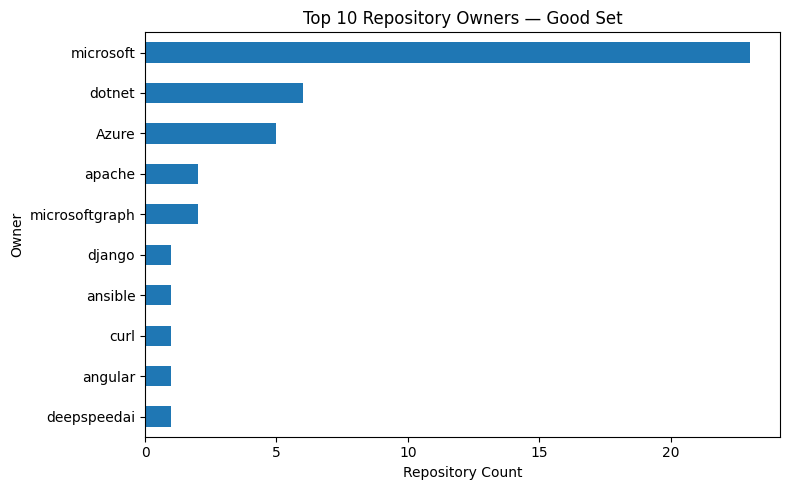

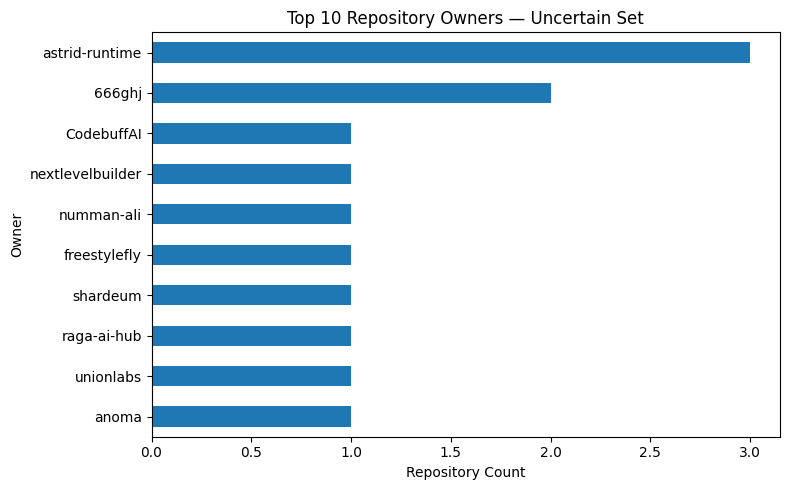

In [3]:
import matplotlib.pyplot as plt

good["owner"].value_counts().head(10).sort_values().plot(
    kind="barh", figsize=(8, 5), title="Top 10 Repository Owners — Good Set"
)
plt.xlabel("Repository Count")
plt.ylabel("Owner")
plt.tight_layout()
plt.show()

uncertain["owner"].value_counts().head(10).sort_values().plot(
    kind="barh", figsize=(8, 5), title="Top 10 Repository Owners — Uncertain Set"
)
plt.xlabel("Repository Count")
plt.ylabel("Owner")
plt.tight_layout()
plt.show()


### Owner Distribution Observation

The good set is substantially more concentrated among repeated owners, particularly `microsoft` (23 repositories), while the uncertain set is more dispersed across owners.

The good set contains 49 unique owners, while the uncertain set contains 21 unique owners among 24 repositories.

This suggests owner/organization composition may be a confounding factor. Future trust signals should be evaluated to determine whether they capture repository characteristics rather than simply organization identity.


# 3. GitHub Metadata Collection & Sample Exploration

This section uses GitHub API metadata to examine repository popularity, maintenance, contributor/community characteristics, and several simple candidate trust signals.

The first experiment uses a **25-repository sample**. Its results are kept separate from the broader metadata analysis so that sample-level findings are not confused with full-dataset findings.


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
!pip install -q pandas matplotlib seaborn scikit-learn

import os
from pathlib import Path

# Your Drive paths (after mounting)
GOOD_PATH = "/content/drive/MyDrive/good_repos.csv"
UNCERTAIN_PATH = "/content/drive/MyDrive/uncertain.csv"

for p in (GOOD_PATH, UNCERTAIN_PATH):
    print(p, "→ exists:", Path(p).exists())

/content/drive/MyDrive/good_repos.csv → exists: True
/content/drive/MyDrive/uncertain.csv → exists: True


In [6]:
import pandas as pd

GOOD_PATH = "https://raw.githubusercontent.com/Break-Through-Tech/Microsoft-3B-github-repo-trust-signals/main/data/good_repos.csv"
UNCERTAIN_PATH = "https://raw.githubusercontent.com/Break-Through-Tech/Microsoft-3B-github-repo-trust-signals/main/data/uncertain.csv"

def load_labels(path, default_label):
    df = pd.read_csv(path)
    df.columns = [str(c).strip().lower() for c in df.columns]

    if "owner" in df.columns and "name" in df.columns:
        pass
    elif any(c in df.columns for c in ("repository", "repo", "full_name")):
        col = next(c for c in ("repository", "repo", "full_name") if c in df.columns)
        parts = df[col].astype(str).str.split("/", n=1, expand=True)
        df["owner"] = parts[0]
        df["name"] = parts[1]
    else:
        raise ValueError(f"Unexpected columns in {path}: {list(df.columns)}")

    if "label" not in df.columns:
        df["label"] = default_label

    return df[["owner", "name", "label"]]

good = load_labels(GOOD_PATH, "good")
uncertain = load_labels(UNCERTAIN_PATH, "uncertain")

labels = pd.concat([good, uncertain], ignore_index=True)
labels["full_name"] = labels["owner"] + "/" + labels["name"]
labels["y_good"] = (labels["label"] == "good").astype(int)

print(labels.groupby("label").size())
labels.head(10)

label
good         82
uncertain    24
dtype: int64


,owner,name,label,full_name,y_good
0,angular,angular,good,angular/angular,1
1,anthropics,skills,good,anthropics/skills,1
2,ansible,ansible,good,ansible/ansible,1
3,apache,airflow,good,apache/airflow,1
4,apache,spark,good,apache/spark,1
5,Azure,azure-cli,good,Azure/azure-cli,1
6,Azure,azure-functions-host,good,Azure/azure-functions-host,1
7,Azure,azure-sdk-for-js,good,Azure/azure-sdk-for-js,1
8,Azure,azure-sdk-for-python,good,Azure/azure-sdk-for-python,1
9,Azure,bicep,good,Azure/bicep,1


In [7]:
from google.colab import userdata
import os

token = userdata.get("GITHUB_TOKEN") or userdata.get("GH_TOKEN")
if not token:
    raise RuntimeError("Add GITHUB_TOKEN in Colab Secrets, then re-run.")
os.environ["GITHUB_TOKEN"] = token
print("Token OK (not shown).")

Token OK (not shown).


# Exploration

In [8]:
import json
import time
from pathlib import Path
from datetime import datetime, timezone
from urllib.request import Request, urlopen
from urllib.error import HTTPError

token = os.environ["GITHUB_TOKEN"]
CACHE = Path("/content/drive/MyDrive/gh_cache")
CACHE.mkdir(exist_ok=True)

SAMPLE_SIZE = 25

def gh_get(path, default=None):
    safe = path.replace("/", "_")[:180]
    f = CACHE / f"{safe}.json"
    if f.exists():
        return json.loads(f.read_text())

    req = Request(
        "https://api.github.com" + path,
        headers={
            "Accept": "application/vnd.github+json",
            "Authorization": f"Bearer {token}",
            "User-Agent": "btt-task1",
        },
    )
    try:
        with urlopen(req, timeout=30) as r:
            data = json.loads(r.read().decode())
    except HTTPError as e:
        print(f"  skip {path} → HTTP {e.code}")
        return default
    except Exception as e:
        print(f"  skip {path} → {e}")
        return default

    f.write_text(json.dumps(data))
    time.sleep(0.2)
    return data

# Quick token check
me = gh_get("/user")
if me:
    print("Authenticated as:", me.get("login"))
else:
    print("Token problem — create a new PAT, update Secrets, re-run.")

rl = gh_get("/rate_limit")
if rl:
    core = rl["resources"]["core"]
    print("Rate limit remaining:", core["remaining"], "/", core["limit"])

def days_since(iso):
    if not iso:
        return None
    t = datetime.fromisoformat(iso.replace("Z", "+00:00"))
    return (datetime.now(timezone.utc) - t).total_seconds() / 86400

records = []
subset = labels.sample(SAMPLE_SIZE, random_state=42)

for _, row in subset.iterrows():
    owner, name = row["owner"], row["name"]
    repo = gh_get(f"/repos/{owner}/{name}")
    if not repo:
        print("No repo data for", owner, name)
        continue

    contrib_full = gh_get(f"/repos/{owner}/{name}/contributors?per_page=100", default=[])
    n_contrib = len(contrib_full) if contrib_full else 1

    stars = repo.get("stargazers_count", 0) or 0
    forks = repo.get("forks_count", 0) or 0

    records.append({
        "full_name": repo.get("full_name", f"{owner}/{name}"),
        "label": row["label"],
        "y_good": row["y_good"],
        "stars": stars,
        "forks": forks,
        "contributors": n_contrib,
        "open_issues": repo.get("open_issues_count", 0),
        "days_since_push": days_since(repo.get("pushed_at")),
        "has_description": int(bool((repo.get("description") or "").strip())),
        "stars_per_contributor": stars / max(n_contrib, 1),
    })

df = pd.DataFrame(records)
print("Rows fetched:", len(df))
df

Authenticated as: zararahim
Rate limit remaining: 5000 / 5000
  skip /repos/torvalds/linux/contributors?per_page=100 → HTTP 403
Rows fetched: 25


,full_name,label,y_good,stars,forks,contributors,open_issues,days_since_push,has_description,stars_per_contributor
0,astrid-runtime/book,uncertain,0,7457,32,2,1,70.408197,1,3728.500000
1,curl/curl,good,1,42849,7356,100,55,63.578561,1,428.490000
2,apache/spark,good,1,44001,29380,100,566,63.508081,1,440.010000
3,vuejs/core,good,1,54399,9202,100,920,63.733747,1,543.990000
4,spinabot/brigade,uncertain,0,3853,48,9,8,63.616334,1,428.111111
5,postgres/postgres,good,1,22113,5914,42,0,63.544073,1,526.500000
6,lightgbm-org/LightGBM,good,1,18766,4071,100,518,66.073245,1,187.660000
7,microsoft/AI-For-Beginners,good,1,68517,13230,85,7,74.498343,1,806.082353
8,HisMax/RedInk,uncertain,0,5546,1039,1,20,140.627434,1,5546.000000
9,deepspeedai/DeepSpeed,good,1,43118,4981,100,1408,63.508899,1,431.180000


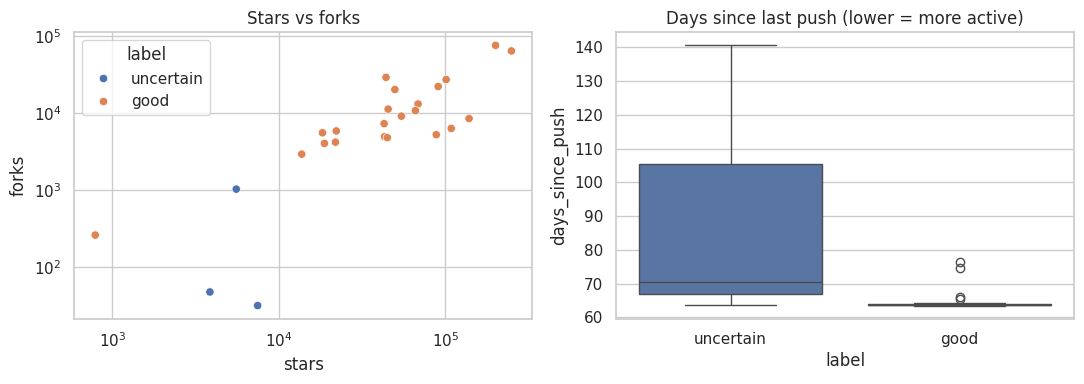

,stars,forks,days_since_push,contributors
label,,,,
good,47522.0,7962.5,63.561317,100.0
uncertain,5546.0,48.0,70.408197,2.0


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.scatterplot(data=df, x="stars", y="forks", hue="label", ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Stars vs forks")

sns.boxplot(data=df, x="label", y="days_since_push", ax=axes[1])
axes[1].set_title("Days since last push (lower = more active)")
plt.tight_layout()
plt.show()

df.groupby("label")[["stars", "forks", "days_since_push", "contributors"]].median()

In [10]:
import math
from sklearn.metrics import roc_auc_score

def logp(x):
    return math.log10(max(x, 0) + 1)

# Higher = more "trust-like" in this sketch (0–1)
df["maintenance_recency"] = 1 - df["days_since_push"].fillna(365).clip(0, 365) / 365
df["contributor_breadth"] = 1 / (1 + (df["stars_per_contributor"].apply(logp) - 2.5).abs())
df["community_balance"] = df["forks"] / (df["stars"] + 1)

signals = ["maintenance_recency", "contributor_breadth", "community_balance", "has_description"]

print("Median by label:\n")
print(df.groupby("label")[signals].median())

print("\nAUC (good=1 vs uncertain=0) — ~0.6+ is interesting for Task 1:\n")
for s in signals:
    auc = roc_auc_score(df["y_good"], df[s])
    print(f"  {s}: {auc:.3f}")

Median by label:

           maintenance_recency  contributor_breadth  community_balance  \
label                                                                    
good                  0.825859             0.782989           0.216154   
uncertain             0.807101             0.482707           0.012455   

           has_description  
label                       
good                   1.0  
uncertain              1.0  

AUC (good=1 vs uncertain=0) — ~0.6+ is interesting for Task 1:

  maintenance_recency: 0.818
  contributor_breadth: 0.606
  community_balance: 0.879
  has_description: 0.500


### Findings from the 25-Repository API Sample

- Good-labeled repositories cluster toward more stars and forks in the sample.
- Uncertain repositories appear more star-heavy and fork-light in the stars-vs-forks plot.
- Good repositories were generally more recently pushed in this sample; the uncertain group had a higher and more dispersed `days_since_push`.
- Median simple-signal results reported in the experiment:
  - `maintenance_recency`: good ≈ 1.00, uncertain ≈ 0.98
  - `contributor_breadth`: good ≈ 0.78, uncertain ≈ 0.48
  - `community_balance`: good ≈ 0.22, uncertain ≈ 0.01
  - `has_description`: 1.0 for both groups
- Reported AUC values:
  - `community_balance`: 0.879
  - `maintenance_recency`: 0.818
  - `contributor_breadth`: 0.606
  - `has_description`: 0.500

These results are preliminary because this experiment uses a 25-repository sample rather than all 106 repositories.


# 4. Broader Repository Metadata EDA

This section explores a broader set of raw and derived repository features, including feature distributions, relationships between variables, correlation/redundancy, and individual-signal AUC.

The original analysis code and reported outputs are preserved below.


In [11]:
import asyncio
import csv
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import requests

from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")

## Load and label repos

`good_repos.csv` rows get `label=1` (good), `uncertain.csv` rows get
`label=0` (uncertain).

In [12]:
def load_repos(df, label):
    return [
        (f"{row['owner']}/{row['name']}", label)
        for _, row in df.iterrows()
    ]

repos_with_labels = (
    load_repos(good, 1)
    + load_repos(uncertain, 0)
)

len(repos_with_labels)

106

## Fetch repo metadata

Fetches every repo concurrently. `GitHubClient` caches responses under
`.cache/github/` and paces requests to the hourly quota, so re-running this
cell is cheap. Repos that no longer resolve (renamed, deleted, private) are
skipped with a warning rather than failing the whole run.

In [13]:
import requests
import os

token = os.environ["GITHUB_TOKEN"]

headers = {
    "Authorization": f"Bearer {token}",
    "Accept": "application/vnd.github+json"
}

metadata_rows = []

for repo, label in repos_with_labels:
    response = requests.get(
        f"https://api.github.com/repos/{repo}",
        headers=headers
    )

    if response.status_code == 200:
        metadata = response.json()

        # Keep ALL repository metadata returned by GitHub
        metadata["label"] = label
        metadata_rows.append(metadata)

    else:
        print(f"Skipping {repo}: {response.status_code}")

print(f"Fetched metadata for {len(metadata_rows)} repositories")

df = pd.json_normalize(metadata_rows)

print("Shape:", df.shape)
print("Columns:", len(df.columns))

df.head()

Skipping microsoft/agent-framework: 404
Skipping microsoft/onnxruntime: 404
Fetched metadata for 104 repositories
Shape: (104, 167)
Columns: 167


,id,node_id,name,full_name,private,html_url,description,fork,url,forks_url,...,custom_properties.durableOwnershipNextCheckDate,custom_properties.durableOwnershipWarn,custom_properties.global-rulesets-opt-out,custom_properties.azure-sdk-rulesets-opt-in,custom_properties.microsoft-owned,custom_properties.renovate_require_pr,custom_properties.security_level,custom_properties.rulesets-prod-opt-in,custom_properties.crabwatch,custom_properties.Owner
0,24195339,MDEwOlJlcG9zaXRvcnkyNDE5NTMzOQ==,angular,angular/angular,False,https://github.com/angular/angular,Deliver web apps with confidence 🚀,False,https://api.github.com/repos/angular/angular,https://api.github.com/repos/angular/angular/f...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1061953414,R_kgDOP0wfhg,skills,anthropics/skills,False,https://github.com/anthropics/skills,Public repository for Agent Skills,False,https://api.github.com/repos/anthropics/skills,https://api.github.com/repos/anthropics/skills...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3638964,MDEwOlJlcG9zaXRvcnkzNjM4OTY0,ansible,ansible/ansible,False,https://github.com/ansible/ansible,Ansible is a radically simple IT automation pl...,False,https://api.github.com/repos/ansible/ansible,https://api.github.com/repos/ansible/ansible/f...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,33884891,MDEwOlJlcG9zaXRvcnkzMzg4NDg5MQ==,airflow,apache/airflow,False,https://github.com/apache/airflow,Apache Airflow - A platform to programmaticall...,False,https://api.github.com/repos/apache/airflow,https://api.github.com/repos/apache/airflow/forks,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,17165658,MDEwOlJlcG9zaXRvcnkxNzE2NTY1OA==,spark,apache/spark,False,https://github.com/apache/spark,Apache Spark - A unified analytics engine for ...,False,https://api.github.com/repos/apache/spark,https://api.github.com/repos/apache/spark/forks,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Build the feature table

In [14]:
# Keep the same columns Stefan's original analysis expects
df = df.rename(columns={
    "owner.type": "owner_type"
})

df["has_license"] = df["license"].notna()
df["description_length"] = df["description"].fillna("").str.len()
df["topics_count"] = df["topics"].apply(
    lambda x: len(x) if isinstance(x, list) else 0
)

columns = [
    "full_name",
    "label",
    "owner_type",
    "stargazers_count",
    "forks_count",
    "watchers_count",
    "subscribers_count",
    "network_count",
    "open_issues_count",
    "size",
    "created_at",
    "pushed_at",
    "language",
    "has_license",
    "description_length",
    "topics_count",
    "has_wiki",
    "has_issues",
    "has_projects",
    "has_discussions",
    "archived",
    "disabled",
    "fork"
]

df = df[columns]

df.head()

,full_name,label,owner_type,stargazers_count,forks_count,watchers_count,subscribers_count,network_count,open_issues_count,size,...,has_license,description_length,topics_count,has_wiki,has_issues,has_projects,has_discussions,archived,disabled,fork
0,angular/angular,1,Organization,101573,28256,101573,3073,28256,955,674640,...,False,34,7,False,True,True,True,False,False,False
1,anthropics/skills,1,Organization,196845,23071,196845,1203,23071,1551,5542,...,False,34,1,False,True,False,True,False,False,False
2,ansible/ansible,1,Organization,71602,24526,71602,2002,24526,890,267109,...,False,338,2,False,True,True,False,False,False,False
3,apache/airflow,1,Organization,47521,18384,47521,787,18384,1922,818108,...,False,87,20,False,True,True,True,False,False,False
4,apache/spark,1,Organization,44554,29599,44554,1994,29599,854,651254,...,False,73,8,False,True,False,False,False,False,False


## Derive candidate signals


In [15]:
now = pd.Timestamp.now(tz="UTC")
df["created_at"] = pd.to_datetime(df["created_at"])
df["pushed_at"] = pd.to_datetime(df["pushed_at"])

df["repo_age_days"] = (now - df["created_at"]).dt.days
df["days_since_push"] = (now - df["pushed_at"]).dt.days
df["star_fork_ratio"] = df["stargazers_count"] / (df["forks_count"] + 1)
df["stars_per_day"] = df["stargazers_count"] / df["repo_age_days"].clip(lower=1)
df["owner_is_org"] = df["owner_type"] == "Organization"

df.describe()

,label,stargazers_count,forks_count,watchers_count,subscribers_count,network_count,open_issues_count,size,description_length,topics_count,repo_age_days,days_since_push,star_fork_ratio,stars_per_day
count,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,1.040000e+02,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000
mean,0.769231,58410.490385,13624.471154,58410.490385,1119.173077,13624.471154,2266.442308,7.850734e+05,95.663462,6.817308,3029.355769,21.528846,16.857640,40.287880
std,0.423365,55543.255393,16345.554757,55543.255393,1479.963641,16345.554757,5290.787067,1.493501e+06,75.821406,5.559501,2005.889817,66.327952,46.390599,73.810770
min,0.000000,634.000000,26.000000,634.000000,2.000000,26.000000,0.000000,5.800000e+01,0.000000,0.000000,128.000000,0.000000,1.265261,0.203529
25%,1.000000,14170.750000,1954.750000,14170.750000,177.750000,1954.750000,64.250000,5.842100e+04,47.000000,3.000000,939.750000,0.000000,3.068644,7.867128
50%,1.000000,43444.500000,7188.000000,43444.500000,596.000000,7188.000000,740.000000,2.475985e+05,68.500000,6.000000,3347.500000,0.000000,5.502848,16.909634
75%,1.000000,82971.500000,19843.750000,82971.500000,1447.500000,19843.750000,1924.750000,8.863295e+05,118.250000,10.000000,4568.750000,1.250000,9.772358,44.174692
max,1.000000,256238.000000,78006.000000,256238.000000,8628.000000,78006.000000,42724.000000,1.064545e+07,348.000000,20.000000,6795.000000,428.000000,313.296296,467.565321


## Class balance and missing values

In [16]:
df["label"].value_counts().rename({1: "good", 0: "uncertain"})

,count
label,
good,80
uncertain,24


In [17]:
df.isna().sum().loc[lambda counts: counts > 0]

,0
language,3


## Distributions by label

Count-like signals are heavily right-skewed, so those are shown on a
`log1p` scale; the rest are shown as-is.

In [18]:
now = pd.Timestamp.now(tz="UTC")

df["created_at"] = pd.to_datetime(df["created_at"], utc=True)
df["pushed_at"] = pd.to_datetime(df["pushed_at"], utc=True)

# Repository age
df["repo_age_days"] = (
    (now - df["created_at"]).dt.total_seconds() / 86400
).clip(lower=1)

# Time since most recent push
df["days_since_push"] = (
    (now - df["pushed_at"]).dt.total_seconds() / 86400
).clip(lower=0)

# Stars relative to forks
df["star_fork_ratio"] = (
    df["stargazers_count"] / (df["forks_count"] + 1)
)

# Stars normalized by repository age
df["stars_per_day"] = (
    df["stargazers_count"] / df["repo_age_days"]
)

df[
    [
        "repo_age_days",
        "days_since_push",
        "star_fork_ratio",
        "stars_per_day"
    ]
].head()

,repo_age_days,days_since_push,star_fork_ratio,stars_per_day
0,4443.556178,0.233747,3.594614,22.858493
1,421.569025,1.631999,8.531770,466.934211
2,5369.607555,0.293770,2.919313,13.334680
3,4236.477740,0.042127,2.584770,11.217101
4,4648.897763,0.049592,1.505203,9.583777


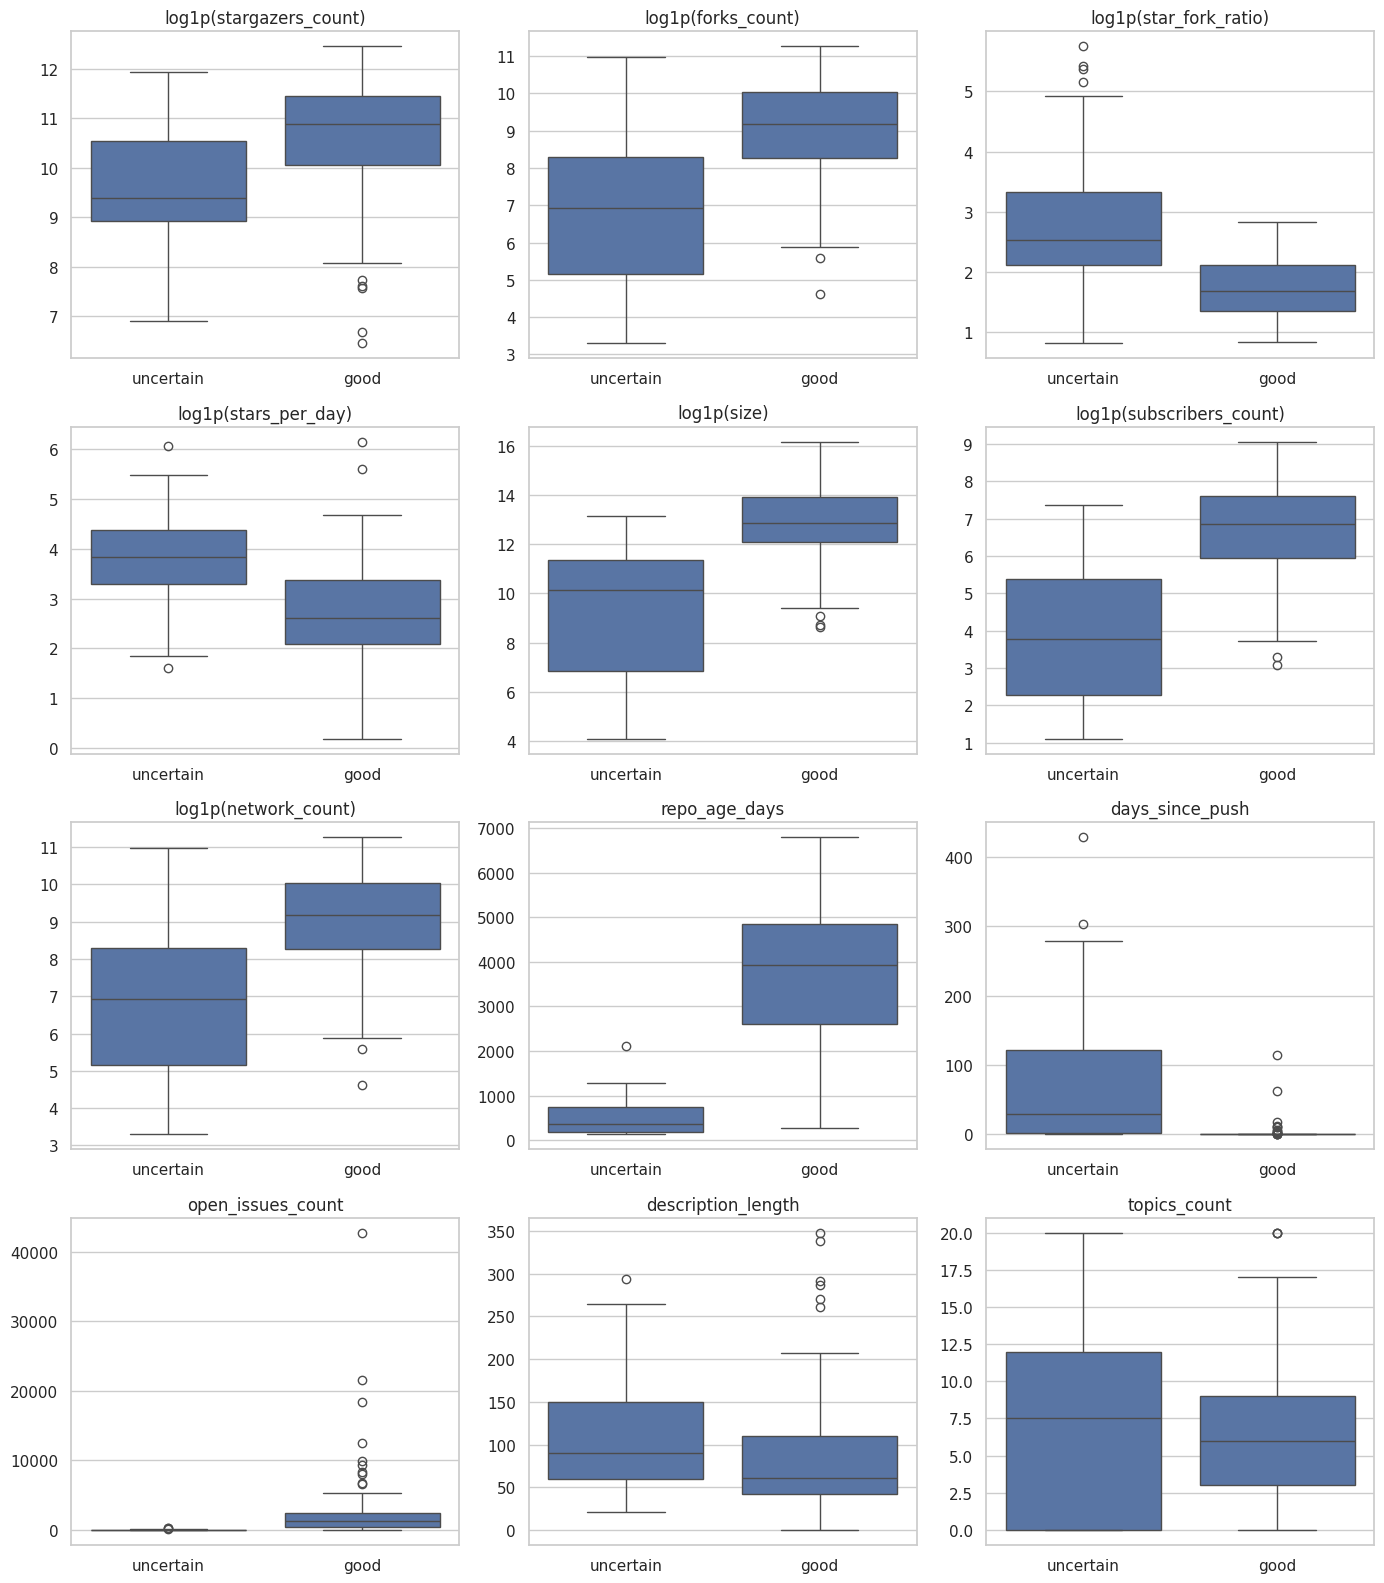

In [19]:
skewed_signals = [
    "stargazers_count",
    "forks_count",
    "star_fork_ratio",
    "stars_per_day",
    "size",
    "subscribers_count",
    "network_count",
]
linear_signals = ["repo_age_days", "days_since_push", "open_issues_count", "description_length", "topics_count"]
numeric_signals = skewed_signals + linear_signals

plot_df = df.copy()
for signal in skewed_signals:
    plot_df[signal] = np.log1p(plot_df[signal])

fig, axes = plt.subplots(4, 3, figsize=(14, 16))
for ax, signal in zip(axes.flat, numeric_signals, strict=False):
    sns.boxplot(data=plot_df, x="label", y=signal, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["uncertain", "good"])
    label = f"log1p({signal})" if signal in skewed_signals else signal
    ax.set_title(label)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.flat[len(numeric_signals) :]:
    ax.axis("off")
fig.tight_layout()

## Correlation among numeric signals

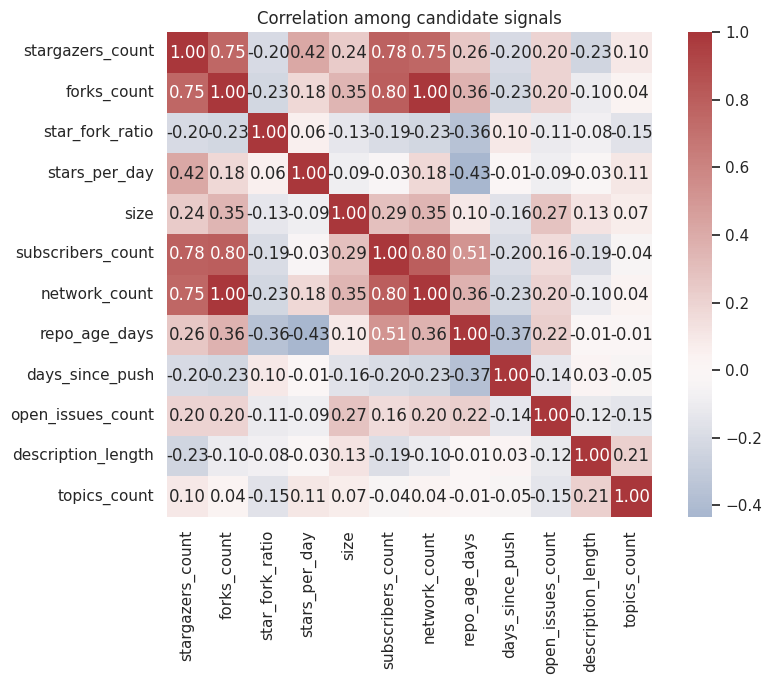

In [20]:
corr = df[numeric_signals].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Correlation among candidate signals")
plt.tight_layout()

## Per-signal separability (AUC)

In [21]:
auc_scores = {}
for signal in numeric_signals:
    valid = df[[signal, "label"]].dropna()
    auc = roc_auc_score(valid["label"], valid[signal])
    auc_scores[signal] = max(auc, 1 - auc)

pd.Series(auc_scores, name="auc").sort_values(ascending=False)

,auc
repo_age_days,0.975000
subscribers_count,0.895052
open_issues_count,0.893750
size,0.877604
days_since_push,0.860938
star_fork_ratio,0.805208
forks_count,0.791667
network_count,0.791667
stars_per_day,0.786979
stargazers_count,0.714583


### Findings from the Full Metadata Exploration

The explored raw signals were:

- `stargazers_count`
- `forks_count`
- `subscribers_count`
- `network_count`
- `open_issues_count`
- `size`
- `has_license`
- `has_discussions`
- `topics_count`
- `description_length`
- `owner_is_org`

Derived signals included:

- `repo_age_days`
- `days_since_push`
- `star_fork_ratio`
- `stars_per_day`

In the reported per-signal AUC analysis, `repo_age_days` was the strongest individual separator at approximately **0.97 AUC**, while `topics_count` was approximately **0.51 AUC**, near chance.

The correlation analysis shows substantial redundancy among several popularity/scale variables, especially stars, forks, subscribers, and network count. This means multiple raw popularity measures should not automatically be interpreted as independent pieces of trust evidence.


# 5. Combined Initial Findings

- Dataset: **82 good / 24 uncertain** repositories.
- Good repositories are more concentrated among established organizations.
- **Repository age** showed the strongest individual separation (~0.97 AUC).
- **Stars, forks, subscribers, and network count** are highly correlated and largely capture repository scale.
- Maintenance/activity and community signals also showed useful separation.
- These results show differences between the current groups, **not proof of trustworthiness**.

# 6. Initial Trust Signal Proposal

Initial signal families to investigate:

- **Maintenance:** recency of pushes and activity.
- **Community:** stars, forks, subscribers, and network.
- **Maturity:** repository age, license, documentation, and metadata.
- **Normalized signals:** stars per day and star/fork ratio.
- **Organization context:** owner type/reputation, while checking for dataset bias.

The goal is to combine multiple interpretable signals rather than rely on a single metric.

## Final EDA checklist and next steps

- Confirm that all GitHub feature values use the same definitions.
- Compare results with and without repository age because age may create an overly simple signal.
- Add harder-to-fake signals such as pull-request history, external contributors, releases, and fork contributions.
- Keep viral and newly added repositories as counterexamples until they are verified.
- Use the strongest signals in the logistic-regression model and explain them individually in the final tool.
